# Exercises week 35

**FYS-STK3155/4155 — Applied Data Analysis and Machine Learning**

**August 24–30, 2026. Deadline: Friday August 28 at midnight.**

Reading for this set: the book, Chapter 3 (in particular Sections 3.1–3.7 from
week 34 and Sections 3.7–3.10 and 3.13 from this week), and the week 35 slides
(`week35slides.pdf`, `week35tuesday.pdf`). The Tuesday session and its notebook
(`week35tuesday.ipynb`) walk through most of the code you need here. For
exercise 1 the book by Faisal, Ong and Deisenroth, *Mathematics for Machine
Learning*, chapter 5 (sections 5.3–5.5) at https://mml-book.github.io/ is very
useful.

## Exercise 1: Analytical exercises

In this exercise we derive the expressions for various derivatives of products of
vectors and matrices. Such derivatives are central to the optimization of various
cost functions. Although we will often use automatic differentiation in actual
calculations, having the analytical expressions is extremely helpful in case we
have simpler derivatives, as well as when we analyze various properties (like
second derivatives) of the chosen cost functions. Vectors are always written as
boldfaced lower-case letters and matrices as upper-case boldfaced letters.
Note that throughout we use the numerator (Jacobian) layout, in which the derivative of a
*scalar* with respect to a vector is a **row** vector — consistent with the example
$\partial(\boldsymbol{A}\boldsymbol{x})/\partial\boldsymbol{x}=\boldsymbol{A}$ in the hint below and with Faisal et al.; if you prefer the
column-gradient convention you will obtain the equivalent transposed results, e.g.
$(\boldsymbol{A}+\boldsymbol{A}^T)\boldsymbol{a}$ instead of $\boldsymbol{a}^T(\boldsymbol{A}+\boldsymbol{A}^T)$.

Show that

$$
\frac{\partial (\boldsymbol{a}^T\boldsymbol{x})}{\partial \boldsymbol{x}} = \boldsymbol{a}^T,
$$

and

$$
\frac{\partial (\boldsymbol{a}^T\boldsymbol{A}\boldsymbol{a})}{\partial \boldsymbol{a}} = \boldsymbol{a}^T\left(\boldsymbol{A}+\boldsymbol{A}^T\right),
$$

and

$$
\frac{\partial \left(\boldsymbol{x}-\boldsymbol{A}\boldsymbol{s}\right)^T\left(\boldsymbol{x}-\boldsymbol{A}\boldsymbol{s}\right)}{\partial \boldsymbol{s}} = -2\left(\boldsymbol{x}-\boldsymbol{A}\boldsymbol{s}\right)^T\boldsymbol{A},
$$

and finally find the second derivative of this function with respect to the vector
$\boldsymbol{s}$.

If we replace the vector $\boldsymbol{s}$ with the unknown parameters
$\boldsymbol{\theta}$ used to define the ordinary least squares method, we end up
with the equations that determine these parameters. The matrix $\boldsymbol{A}$ is
then the design matrix $\boldsymbol{X}$, and $\boldsymbol{x}$ has to be replaced
with the outputs $\boldsymbol{y}$. The second derivative of the mean squared error
is then proportional to the Hessian matrix
$\boldsymbol{H}=\boldsymbol{X}^T\boldsymbol{X}$.

**Hint:** it is always useful to write out with summation indices the various
quantities; take a look at the examples in the week 35 slides. As an example,
consider the function

$$
f(\boldsymbol{x}) = \boldsymbol{A}\boldsymbol{x},
$$

which reads for a specific component $f_i$ (defining $\boldsymbol{A}$ to be an
$n\times n$ matrix and $\boldsymbol{x}$ a vector of length $n$)

$$
f_i = \sum_{j=0}^{n-1} a_{ij} x_j,
$$

which leads to

$$
\frac{\partial f_i}{\partial x_j} = a_{ij},
$$

and written out in terms of the vector $\boldsymbol{x}$ we have

$$
\frac{\partial f(\boldsymbol{x})}{\partial \boldsymbol{x}} = \boldsymbol{A}.
$$

## Exercise 2: Making your own data and exploring scikit-learn

We will generate our own dataset for a function $y(x)$ where $x\in[0,1]$ and
defined by random numbers computed with the uniform distribution. The function $y$
is a quadratic polynomial in $x$ with added stochastic noise according to the
normal distribution $\mathcal{N}(0,1)$. The following simple Python instructions
define our $x$ and $y$ values (with 100 data points).

In [1]:
import numpy as np

rng = np.random.default_rng(2026)
x = rng.random((100, 1))
y = 2.0 + 5.0 * x * x + 0.1 * rng.standard_normal((100, 1))

1. Write your own code (following the examples in the book, Chapter 3, and the
   week 34–35 slides) for computing the parametrization of the data set, fitting a
   second-order polynomial. That is, set up the design matrix
   $\boldsymbol{X}$ with columns $1, x, x^2$ and find the optimal parameters
   $\boldsymbol{\theta}$ from the normal equations (or, better, through the SVD —
   see the week 34 discussion of why we never invert
   $\boldsymbol{X}^T\boldsymbol{X}$).

2. Use thereafter **scikit-learn** (see the examples in the week 35 slides and the
   Tuesday notebook) and compare with your own code. Note that scikit-learn does
   not, by default, include the intercept in the design matrix. See the
   discussions on scaling your data in the week 35 slides (and Section 3.13 of the
   book). This type of problem appears in particular if we fit a polynomial with
   an intercept.

3. Using scikit-learn, compute also the mean squared error, a risk metric
   corresponding to the expected value of the squared (quadratic) error

$$
MSE(\boldsymbol{y},\tilde{\boldsymbol{y}}) = \frac{1}{n}\sum_{i=0}^{n-1}\left(y_i-\tilde{y}_i\right)^2,
$$

   and the $R^2$ score function. If $\tilde{y}_i$ is the predicted value of the
   $i$-th sample and $y_i$ is the corresponding true value, then the $R^2$ score is

$$
R^2(\boldsymbol{y},\tilde{\boldsymbol{y}}) = 1 - \frac{\sum_{i=0}^{n-1}(y_i-\tilde{y}_i)^2}{\sum_{i=0}^{n-1}(y_i-\bar{y})^2},
$$

   where the mean value of $\boldsymbol{y}$ is

$$
\bar{y} = \frac{1}{n}\sum_{i=0}^{n-1} y_i.
$$

   You can use the functionality included in scikit-learn, or your own functions
   from the Tuesday notebook. Discuss the meaning of these results. Try also to
   vary the coefficient in front of the added stochastic noise term and discuss
   the quality of the fits.

In [2]:
# Your code for exercise 2 here
from sklearn.linear_model import LinearRegression 
from sklearn.metrics import mean_squared_error, r2_score

#2nd order polynomial design matrix:
X = np.vander(x[:,0], 3, increasing=True)
print(X.shape)

#Function for OLS through SVD
def ols(X, y):
    """Ordinary least squares through the SVD"""
    U, s, Vt = np.linalg.svd(X, full_matrices=False)
    return Vt.T @ (U.T @ y / s)

print("Theta from SVD, OLS:" , ols(X,y[:,0]))

#Get the theta values from SVD
theta = ols(X,y[:,0])
#Predicted y
y_tilde = X @ theta

#Using scikit-learn to get the OLS:
linreg = LinearRegression()
linreg.fit(X,y)

print("The intercept is: ", linreg.fit(X,y).intercept_)
print("The coefficients are: ", linreg.fit(X,y).coef_)

#Predicted y based on scikit learn calculation
ypredict = linreg.predict(X)

print(f"Mean squared error (Scikit): {mean_squared_error(y, ypredict):.3f}")
print(f"Mean squared error (SVD calc): {mean_squared_error(y, y_tilde):.3f}")

print(f"Coefficient of determination (Scikit): {r2_score(y, ypredict):.3f}")
print(f"Coefficient of determination (SVD calc): {r2_score(y, y_tilde):.3f}")
print("\n")
print("It is a very good fit. Increasing the noise results in worse results \n (higher MSE and lower r2), while removing the noise gives a perfect fit.")


(100, 3)
Theta from SVD, OLS: [ 2.02956252 -0.04832909  5.01856665]
The intercept is:  [2.02956252]
The coefficients are:  [[ 0.         -0.04832909  5.01856665]]
Mean squared error (Scikit): 0.014
Mean squared error (SVD calc): 0.014
Coefficient of determination (Scikit): 0.993
Coefficient of determination (SVD calc): 0.993


It is a very good fit. Increasing the noise results in worse results 
 (higher MSE and lower r2), while removing the noise gives a perfect fit.


## Exercise 3: Split data in test and training data

In this exercise we want you to compute the MSE for the training data and the test
data as a function of the complexity of a polynomial, that is the degree of a given
polynomial.

The aim is to reproduce Figure 2.11 of Hastie et al., *The Elements of Statistical
Learning*. Feel free to read the discussions leading to that figure.

Our data is defined by $x\in[-3,3]$ with a total of, for example, $n=100$ data
points. You should try to vary the number of data points $n$ in your analysis.

In [3]:
n = 100
x = np.linspace(-3, 3, n).reshape(-1, 1)
y = np.exp(-x**2) + 1.5 * np.exp(-(x - 2)**2) + rng.normal(0, 0.1, x.shape)

where $y$ is the function we want to fit with a given polynomial.

1. Write a first code which sets up a design matrix $\boldsymbol{X}$ defined by a
   fifth-order polynomial and split your data set into training and test data
   (`sklearn.model_selection.train_test_split` is fine).

2. Write thereafter (using either scikit-learn or your matrix inversion/SVD code)
   an ordinary least squares fit and compute the mean squared error for the
   training data and the test data. These calculations should apply to a model
   given by a fifth-order polynomial. If you compare your own code with
   scikit-learn, note that the latter does not include the intercept by default —
   see the discussions on scaling in the week 35 slides.

3. Add now a model which allows you to make polynomials up to degree $15$. Perform
   a standard OLS fit of the training data and compute the MSE for the training
   and test data and plot both as functions of the polynomial degree. Compare what
   you see with Figure 2.11 of Hastie et al. Comment on your results. For which
   polynomial degree do you find the optimal (smallest) test MSE?

The MSE for training data with a 6 polynomial fit is 0.034
The MSE for test data with a 6 polynomial fit is 0.023


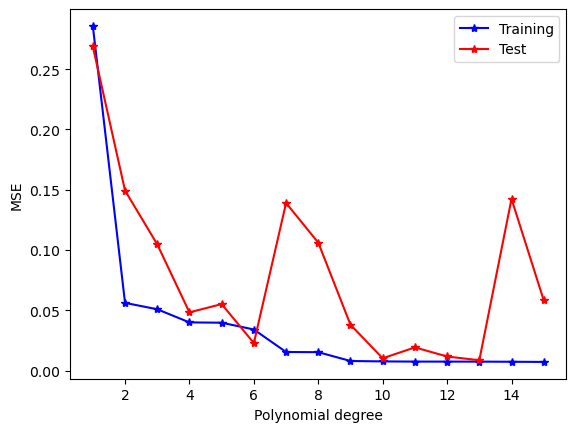

In [4]:
# Your code for exercise 3 here

from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt

#Splitting data into test and train data
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.3,random_state=2026)

#Fifth order polynomial
d = 6

#Design matrix on the training data:
X_train = np.vander(x_train[:,0], d, increasing=True)
#Design matrix on the test data:
X_test = np.vander(x_test[:,0], d, increasing=True)

theta = ols(X_train,y_train[:,0])

#Calculate the MSE:
MSE_train = (mean_squared_error(y_train, X_train @ theta))
MSE_test = (mean_squared_error(y_test,  X_test @ theta))

print(f"The MSE for training data with a {d} polynomial fit is {MSE_train:.3f}")
print(f"The MSE for test data with a {d} polynomial fit is {MSE_test:.3f}")

#Adding a model to perform OLS for polynomials up to degree 15
mse_train = []
mse_test = []
for d in range(1,16):
    #Design matrix on the training data:
    X_train = np.vander(x_train[:,0], d, increasing=True)

    #Design matrix on the test data:
    X_test = np.vander(x_test[:,0], d, increasing=True)
    
    #calculate OLS theta
    theta = ols(X_train,y_train[:,0])

    #Calculate the MSE:
    mse_train.append(mean_squared_error(y_train, X_train @ theta))
    mse_test.append(mean_squared_error(y_test,  X_test @ theta))


#Plotting the MSE as a function of polynomial degree
xx = np.linspace(1,15,15)

plt.plot(xx,mse_train,"b*-",label="Training")
plt.plot(xx,mse_test,"r*-",label="Test")
plt.ylabel("MSE")
plt.xlabel("Polynomial degree")
plt.legend()
plt.show()

### Comment on figure:
The figure follows generally the same pattern as Fig. 2.11, where the training sample gets lower MSE for higher polynomials, while the test sample shows a "U" shape. Our figure shows two locations of minimum points on the test sample while fig. 2.11 only shows one. We think the polynomial of degree 5 (d=6) has the optimal test MSE.

## Exercise 4 (optional): a first taste of Ridge

This voluntary exercise connects directly to Monday's lecture and to Case 4 of the
Tuesday notebook; it is also a useful warm-up for Project 1.

Keep the data set and the degree-15 design matrix from exercise 3, standardise the
feature columns (training statistics only!), and replace OLS by Ridge regression,

$$
\hat{\boldsymbol{\theta}}_{\mathrm{Ridge}} = \left(\boldsymbol{X}^T\boldsymbol{X}+\lambda\boldsymbol{I}\right)^{-1}\boldsymbol{X}^T\boldsymbol{y}.
$$

1. Plot the training and test MSE as functions of $\lambda$ on a logarithmic grid,
   say $\lambda\in[10^{-8},10^{4}]$. Do you find the U-shape discussed in the
   lecture?

2. Compare your best test MSE with the best value found in exercise 3 by varying
   the polynomial degree. Two dials, one phenomenon — which gives the finer
   control?

3. Check explicitly that your training MSE is monotonically increasing in
   $\lambda$, and explain in one sentence why it must be.

Minimum MSE is  0.13522575048235516 at lambda = 6.309573444801943 for training data
Minimum MSE is  0.10928873617630307 at lambda = 2.5118864315095824 for test data


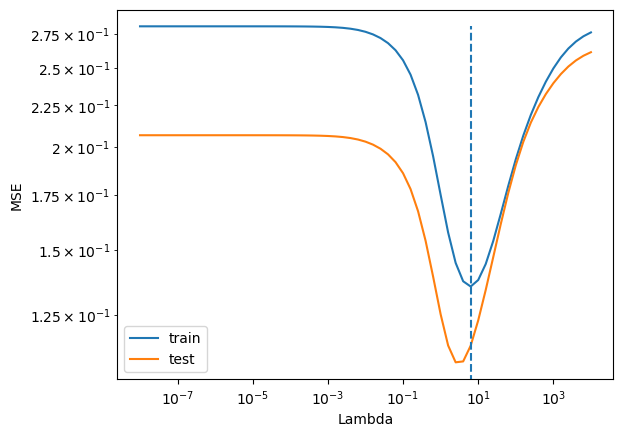

In [5]:
# Your code for exercise 4 here
from sklearn.linear_model import Ridge

X_train = np.vander(x_train[:,0], 15, increasing=True)

#standardise
mu, sd = X_train[:, 1:].mean(axis=0), X_train[:, 1:].std(axis=0)
X_trains, X_tests = (X_train[:, 1:] - mu) / sd, (X_test[:, 1:] - mu) / sd
#X_trains = (X_train[:, 1:] - mu) / sd 

#Get the mean y and centered y
ym = y_train.mean()
yc = y_train - ym

#Loop through different lambdas and calculate the Ridge regression and MSE
lambdas = np.logspace(-8, 4, 61)
mse_train = []
mse_test = []
for l in lambdas:
    #Theta from Ridge
    theta = Ridge(alpha=l, fit_intercept=False).fit(X_train, yc).coef_
    #MSE for train and test data
    mse_train.append(mean_squared_error(y_train, ym + X_trains @ theta[0,1:]))
    mse_test.append(mean_squared_error(y_test,  ym + X_tests @ theta[0,1:]))


#Plot the results
plt.plot(lambdas,mse_train,label="train")
plt.plot(lambdas,mse_test,label="test")
plt.xscale("log"); plt.yscale("log")
plt.ylabel("MSE")
plt.xlabel("Lambda")
plt.legend()
plt.vlines(lambdas[np.argmin(mse_train)],ymin=0,ymax=np.max(mse_train),linestyle="--")

#Finding the minimum MSE and at what lambda
print("Minimum MSE is ",np.min(mse_train), "at lambda =", lambdas[np.argmin(mse_train)], "for training data")
print("Minimum MSE is ",np.min(mse_test), "at lambda =", lambdas[np.argmin(mse_test)], "for test data")
